NOTE: Accuracy sirf ek number hai, aur Day 56B se pata hai ki wo imbalanced data mein dhokha deta hai. Confusion Matrix batata hai ki model kaise sahi aur kaise galat hua. Isme 4 khaane hote hain (positive = churn):

```Conditions           Predicted: Active (0)	     Predicted: Churn (1)
   Actual: Active (0)	TN: sahi, active ko active kaha	FP: galat alarm, active ko churn kaha
   Actual: Churn (1)	FN: churner miss ho gaya	TP: sahi, churner pakda

Yaad rakhne ka tareeka: pehla akshar (T/F) batata hai ki model sahi tha ya galat, doosra (P/N) batata hai ki model ne kya predict kiya.

Aaj ka rule: Test set Day 70 mein ek baar score ho chuka hai. Aaj usi ko sirf samajhne ke liye dekh rahe hain, kisi model ko badalne ke liye nahi. Model chunne ka kaam CV par hota hai, isliye aaj CV-based matrix bhi banayenge.

1. Setup:

In [5]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_predict

X_train = pd.read_csv('../data/processed/X_train.csv')
y_train = pd.read_csv('../data/processed/y_train.csv').squeeze()
X_test = pd.read_csv('../data/processed/X_test.csv')
y_test = pd.read_csv('../data/processed/y_test.csv').squeeze()

models = {
    'Logistic Regression': joblib.load('models/logreg_pipeline.joblib'),
    'Decision Tree (tuned)': joblib.load('models/decision_tree_tuned.joblib'),
}

2. Ek chhote hand-made example se pehle intuition banao:

In [6]:
actual    = [1, 1, 1, 1, 0, 0, 0, 0, 0, 0]
predicted = [1, 1, 0, 0, 0, 0, 0, 0, 1, 1]

tn, fp, fn, tp = confusion_matrix(actual, predicted).ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

TN=4, FP=2, FN=2, TP=2


Haath se gin kar dekho ki yeh numbers sahi hain. ravel() ka order hamesha TN, FP, FN, TP hota hai (sklearn mein row = actual, column = predicted).

3. Apne models ka confusion matrix (test set):

In [7]:
cms = {}
for name, m in models.items():
    pred = m.predict(X_test)
    cms[name] = confusion_matrix(y_test, pred)
    tn, fp, fn, tp = cms[name].ravel()
    print(f"{name}: TN={tn}, FP={fp}, FN={fn}, TP={tp}  (total {tn+fp+fn+tp})")

Logistic Regression: TN=342, FP=117, FN=156, TP=442  (total 1057)
Decision Tree (tuned): TN=338, FP=121, FN=159, TP=439  (total 1057)


Total test set ke size ke barabar aana chahiye. Agar nahi aaya to kuch galat hai.

4. Heatmap (README ke liye bhi kaam aayega):

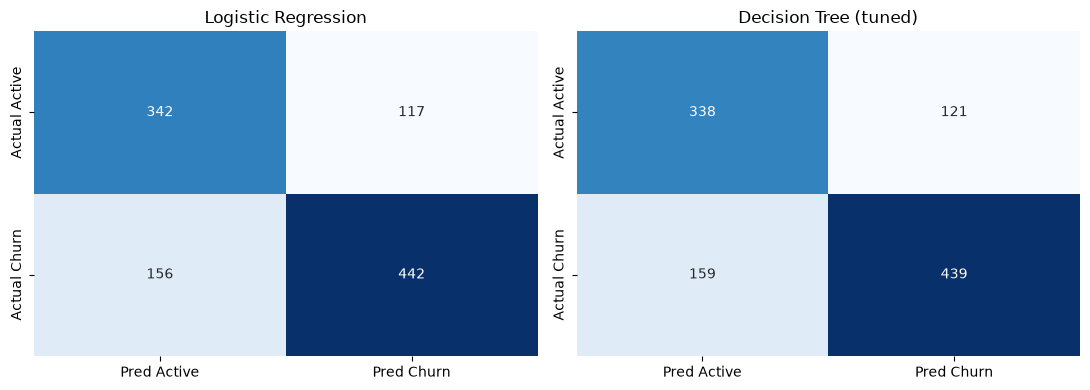

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, cm) in zip(axes, cms.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Pred Active', 'Pred Churn'],
                yticklabels=['Actual Active', 'Actual Churn'])
    ax.set_title(name)
plt.tight_layout()
plt.savefig('../reports/confusion_matrices_test.png', dpi=150)
plt.show()

5. Normalized matrix (counts ki jagah percentage, imbalanced data mein zyada samajh aata hai):

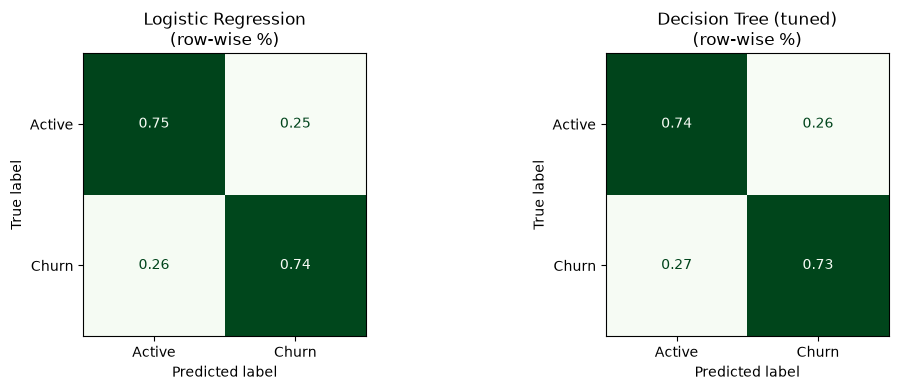

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, m) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(
        m, X_test, y_test, normalize='true', cmap='Greens',
        display_labels=['Active', 'Churn'], ax=ax, values_format='.2f', colorbar=False)
    ax.set_title(f"{name}\n(row-wise %)")
plt.tight_layout()
plt.show()

normalize='true' har row ko 1 par sum karta hai. Neeche wali row (Actual Churn) mein dikhega ki asli churners mein se kitne % pakde gaye (wahi Recall hai, Day 73 mein detail).

6. Matrix se 4 rates nikaalo (sirf definition abhi, formal discussion agle dino mein):

In [11]:
rows = []
for name, cm in cms.items():
    tn, fp, fn, tp = cm.ravel()
    rows.append({
        'model': name,
        'TPR (churners pakde)': tp / (tp + fn),
        'FNR (churners miss)': fn / (tp + fn),
        'FPR (galat alarm)': fp / (fp + tn),
        'TNR (active sahi pehchane)': tn / (tn + fp),
    })
print(pd.DataFrame(rows).set_index('model').round(3))

                       TPR (churners pakde)  FNR (churners miss)  \
model                                                              
Logistic Regression                   0.739                0.261   
Decision Tree (tuned)                 0.734                0.266   

                       FPR (galat alarm)  TNR (active sahi pehchane)  
model                                                                 
Logistic Regression                0.255                       0.745  
Decision Tree (tuned)              0.264                       0.736  


TPR aur FNR ka sum 1 hota hai, aur FPR aur TNR ka bhi.

7. Test set ke sirf ek number par bharosa mat karo, CV se matrix bhi dekho:

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for name, m in models.items():
    oof_pred = cross_val_predict(m, X_train, y_train, cv=cv)   # har customer ki prediction usi fold se jisme wo validation mein tha
    tn, fp, fn, tp = confusion_matrix(y_train, oof_pred).ravel()
    print(f"{name} (CV out-of-fold): TN={tn}, FP={fp}, FN={fn}, TP={tp}")

Logistic Regression (CV out-of-fold): TN=1327, FP=506, FN=670, TP=1723
Decision Tree (tuned) (CV out-of-fold): TN=1242, FP=591, FN=609, TP=1784


cross_val_predict har training customer ke liye ek aisi prediction deta hai jo us customer ko dekhe bina bani thi. Is se matrix ka size test set se kaafi bada hota hai, to numbers zyada stable hote hain.

8. Galtiyon ki cost alag hoti hai (business angle):

In [13]:
# Yeh numbers ASSUMPTIONS hain, apne hisaab se badlo
COST_FN = 50    # churner miss hua: us customer ki lifetime value ka andaza
COST_FP = 5     # galat alarm: faltu discount/email ki cost
BENEFIT_TP = 40 # churner pakda aur retain ho gaya (sab nahi hote, isliye FN se thoda kam rakha)

for name, cm in cms.items():
    tn, fp, fn, tp = cm.ravel()
    net = tp * BENEFIT_TP - fp * COST_FP - fn * COST_FN
    print(f"{name}: net value = {net}")

Logistic Regression: net value = 9295
Decision Tree (tuned): net value = 9005


Yeh numbers sirf tarika dikhane ke liye hain. Asli project mein tum campaign ki real cost aur customer ki average value daaloge. Fir model chunne ka sawaal sirf “kaunsa zyada accurate hai” nahi, balki “kaunsa kam nuksan karta hai” ban jaata hai.

9. Threshold badalne se matrix kaise badalta hai:

In [14]:
proba = models['Logistic Regression'].predict_proba(X_test)[:, 1]

for t in [0.3, 0.5, 0.7]:
    pred_t = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred_t).ravel()
    print(f"threshold={t}: TP={tp}, FP={fp}, FN={fn}, TN={tn}")

threshold=0.3: TP=554, FP=255, FN=44, TN=204
threshold=0.5: TP=442, FP=117, FN=156, TN=342
threshold=0.7: TP=269, FP=52, FN=329, TN=407


Threshold kam karo to zyada customers flag hote hain: TP badhta hai, FN kam hota hai, lekin FP bhi badhta hai. Yeh seesaw hai. Best threshold test set se mat chuno. Agar badalna ho to CV ke out-of-fold probabilities se chuno (Day 74 mein ROC ke saath).

10. Dono models ke galat prediction cases dekho:

In [15]:
pred_lr = models['Logistic Regression'].predict(X_test)
pred_dt = models['Decision Tree (tuned)'].predict(X_test)

look = X_test.copy()
look['actual'] = y_test.values
look['LR'] = pred_lr
look['DT'] = pred_dt

both_missed = look[(look['actual'] == 1) & (look['LR'] == 0) & (look['DT'] == 0)]
print(f"Churners jo DONO models ne miss kiye: {len(both_missed)}")
print(both_missed.describe().loc[['mean', '50%']].round(2))

Churners jo DONO models ne miss kiye: 124
      Recency  Frequency  Monetary_log  AvgOrderValue  Tenure  UniqueProducts  \
mean    84.27       6.06          7.24         384.08  375.37           88.24   
50%     67.50       5.00          7.31         313.70  468.50           73.00   

      actual   LR   DT  
mean     1.0  0.0  0.0  
50%      1.0  0.0  0.0  


Jo churners dono models se miss hote hain, unme koi common pattern hai? (jaise kam Tenure, bahut kam orders). Yeh feature engineering ke naye ideas deta hai.

11. Metrics ka sneak peek (kal se detail):

In [16]:
tn, fp, fn, tp = cms['Logistic Regression'].ravel()
print("Accuracy :", round((tp + tn) / (tp + tn + fp + fn), 3))
print("Precision:", round(tp / (tp + fp), 3), "  (churn bola, to kitni baar sahi)")
print("Recall   :", round(tp / (tp + fn), 3), "  (asli churners mein se kitne pakde)")

Accuracy : 0.742
Precision: 0.791   (churn bola, to kitni baar sahi)
Recall   : 0.739   (asli churners mein se kitne pakde)


Yeh teeno numbers isi 2x2 matrix se bante hain. Day 72-73 mein inko ek-ek karke samjhenge.

practice questions:

1. COST_FN, COST_FP, BENEFIT_TP ko badal kar dekho (jaise COST_FP = 40, matlab campaign mehengi hai). Kya “best model” badal jaata hai? Apne shabdon mein likho ki business context model ke chunav ko kaise badalta hai.

Haan, agar aap costs (COST_FN, COST_FP) ya benefits (BENEFIT_TP) ko badaloge, toh financial calculations ke mutabiq "best model" badal sakta hai.


    - Agar aapki retention campaign ya discount offer bohot mehengi hai (yaani COST_FP high hai), toh woh model sabse danger sabit hoga jo bina baat ke bohot saare active customers ko churner samajh kar mehenge discounts baant de (High False Positives). Is case mein wahi model jeetega jiski Precision behtar ho (yaani jo galat alarm kam de).

    - Iske ulta, agar customer ko khone ka dukh (Customer Lifetime Value loss yani COST_FN) bahut bada hai, toh woh model behtar hoga jo zyada se zyada churners ko pakad le (High Recall / Low FN), chahe thode se false alarms (FPs) extra kyun na jhelne padein.


- Business Context ka Role:
Business mein koi bhi ML model sirf accuracy ya F1-score ke liye nahi banta, balki ROI (Return on Investment) ke liye banta hai. Har business ke unit economics alag hote hain (jaise ek luxury brand ke discounts ki cost alag hoti hai, aur ek SaaS company ke retention offers ki cost alag hoti hai). Isliye business context hi decide karta hai ki model ki kis galti (FP ya FN) ki penalty kitni heavy honi chahiye.

2. Apne shabdon mein likho: tumhare churn project mein FP aur FN mein se kaunsi galti zyada mehengi hai, aur kyun?

Aam taur par, e-commerce aur subscription churn projects mein False Negative (FN) – yani asli churner ko miss kar dena – zyada mehengi galti hoti hai, lekin iske peeche ek balance bhi hota hai:
1. False Negative (FN) kyu mehenga padta hai? (Customer Loss)
- Jab model kisi churner ko pehchan nahi pata aur woh platform chhod kar chala jata hai, toh hum apna ek existing customer kho dete hain.
- Business Impact: Ek naye customer ko acquire karne ki cost (Customer Acquisition Cost - CAC) purane customer ko retain karne se kaafi zyada hoti hai. Saath hi, customer ki long-term value (LTV) ka bhi nuksan hota hai.
2. False Positive (FP) ka kya scene hai? (Galat Alarm)
- Iska matlab hai ki customer active tha, lekin humne use galat samajh kar retention email ya chhota discount coupon bhej diya.
- Business Impact: Iska nuksan sirf ek marketing email ki cost ya ek chote discount ka margin loss hota hai, jo ki aam taur par customer kho dene (FN) ke mukable kaafi kam hota hai.


**Exception:** Agar aapka retention offer itna bada ho ki wo khud ek bada financial burden ban jaye (jaise har "predicted churner" ko 50% cash discount dena), tab False Positives bhi company ke liye kaafi mehnge pad sakte hain. Isiliye threshold tuning aur cost matrix ka use kiya jata hai.